# 16 · HOG features and classical machine learning

**Level:** Advanced / guided expert practice  
**Prerequisites:** Gradients and histograms; NumPy arrays; Basic train/test vocabulary

## What you will build and learn

- Build a labeled synthetic dataset
- Select an SVM using validation data
- Evaluate held-out data and distribution shift

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Define the problem and split first
Classify circle, square, and triangle images. HOG summarizes local edge directions; an SVM learns boundaries between feature vectors. This deliberately small synthetic task is not evidence of real-world recognition ability.

Use independent random streams for training, validation, and testing. Choose hyperparameters with validation accuracy. Inspect test predictions only after choosing the model. Never scatter augmented versions of one source image across splits.


In [2]:
class_names = ['circle', 'square', 'triangle']
def make_shape(label, random, offset_x=0):
    image = np.full((64, 64), random.integers(10, 35), np.uint8)
    center = np.array([32 + offset_x, 32]) + random.integers(-5, 6, 2)
    radius = int(random.integers(14, 22))
    shade = int(random.integers(180, 256))
    angle = random.uniform(-np.pi/5, np.pi/5)
    if label == 0:
        cv2.circle(image, tuple(center), radius, shade, -1, cv2.LINE_AA)
    else:
        count = 4 if label == 1 else 3
        base_angle = np.pi/4 if label == 1 else -np.pi/2
        angles = np.arange(count)*2*np.pi/count + base_angle + angle
        vertices = center + radius*np.column_stack([np.cos(angles), np.sin(angles)])
        cv2.fillConvexPoly(image, vertices.round().astype(np.int32), shade, cv2.LINE_AA)
    return np.clip(image.astype(np.float32)+random.normal(0, 5, image.shape), 0, 255).astype(np.uint8)

def make_dataset(samples_per_class, seed, offset_x=0):
    random = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), samples_per_class).astype(np.int32)
    images = np.stack([make_shape(int(label), random, offset_x) for label in labels])
    order = random.permutation(len(labels))
    return images[order], labels[order]

train_images, y_train = make_dataset(90, 1601)
val_images, y_val = make_dataset(30, 1602)
test_images, y_test = make_dataset(40, 1603)
print('Train / validation / test:', len(y_train), len(y_val), len(y_test))


Train / validation / test: 270 90 120


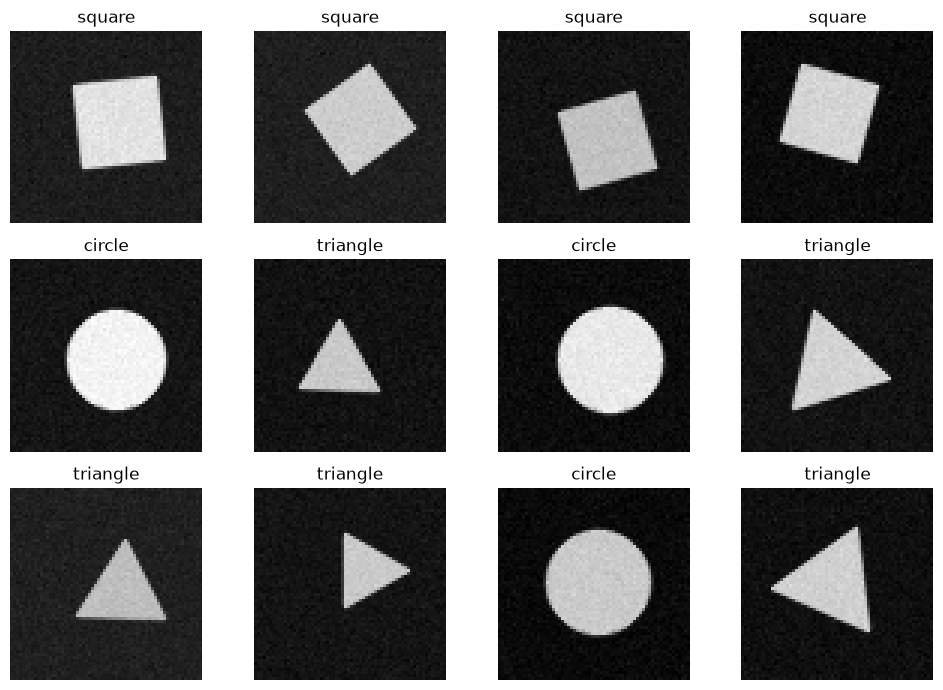

train class counts: [90 90 90]
validation class counts: [30 30 30]
test class counts: [40 40 40]


In [3]:
show_images(list(train_images[:12]), [class_names[i] for i in y_train[:12]], cols=4, figsize=(10, 7))
for split_name, labels in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(split_name, 'class counts:', np.bincount(labels, minlength=3))
train_hashes = {image.tobytes() for image in train_images}
assert not any(image.tobytes() in train_hashes for image in val_images)
assert not any(image.tobytes() in train_hashes for image in test_images)


## Step 2 — Extract HOG
Each 8×8 cell votes gradient strength into nine orientation bins. Overlapping 16×16 blocks normalize contrast. A 64×64 image has 7×7 blocks, each with 2×2 cells: 7×7×2×2×9 = **1764 features**.

HOG depends on position. Centering, scale, and crop policy are part of the model contract. This baseline uses HOG's local block normalization without an additional learned transform.


Training features: (270, 1764) float32


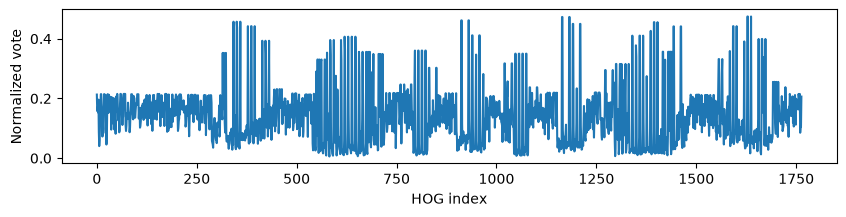

In [4]:
hog = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)
def extract_hog(images):
    return np.stack([hog.compute(np.ascontiguousarray(image)).ravel() for image in images]).astype(np.float32)

X_train, X_val, X_test = map(extract_hog, [train_images, val_images, test_images])
assert X_train.shape == (270, 1764) and np.isfinite(X_train).all()
print('Training features:', X_train.shape, X_train.dtype)
plt.figure(figsize=(10, 2))
plt.plot(X_train[0]); plt.xlabel('HOG index'); plt.ylabel('Normalized vote'); plt.show()


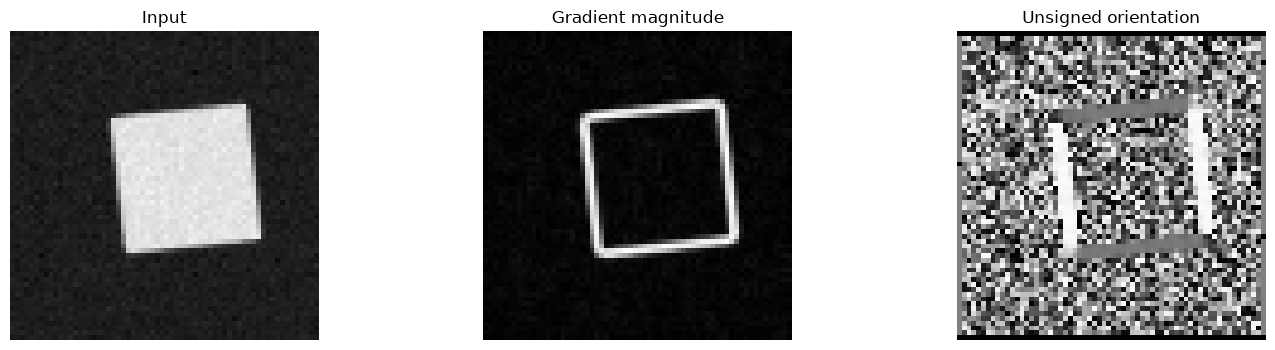

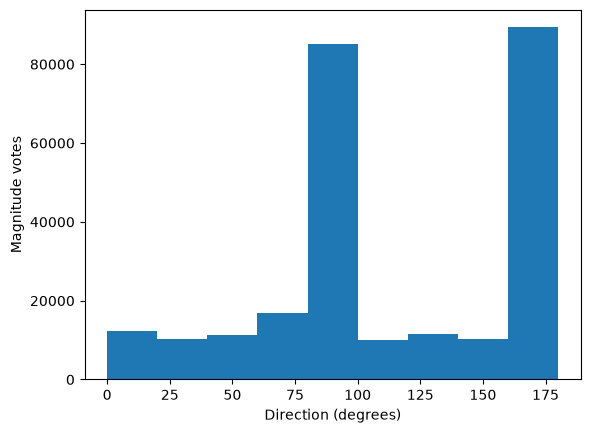

In [5]:
example = train_images[0]
dx = cv2.Sobel(example, cv2.CV_32F, 1, 0)
dy = cv2.Sobel(example, cv2.CV_32F, 0, 1)
strength, direction = cv2.cartToPolar(dx, dy, angleInDegrees=True)
show_images([example, strength, direction % 180], ['Input', 'Gradient magnitude', 'Unsigned orientation'])
plt.hist((direction % 180).ravel(), bins=np.linspace(0, 180, 10), weights=strength.ravel())
plt.xlabel('Direction (degrees)'); plt.ylabel('Magnitude votes'); plt.show()


The global histogram above illustrates voting; it is not the full HOG descriptor. HOG also preserves spatial cells and normalizes blocks. Removing spatial layout loses useful shape information.


## Step 3 — Choose an SVM using validation
A linear SVM seeks a large-margin separating boundary. C controls the penalty for training errors: larger C prioritizes fitting training examples. OpenCV handles multiclass prediction internally through binary classifiers. Labels are integers and features are float32.


In [6]:
def train_svm(features, labels, C):
    model = cv2.ml.SVM_create()
    model.setType(cv2.ml.SVM_C_SVC)
    model.setKernel(cv2.ml.SVM_LINEAR)
    model.setC(float(C))
    model.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER | cv2.TERM_CRITERIA_EPS, 3000, 1e-6))
    assert model.train(features, cv2.ml.ROW_SAMPLE, labels)
    return model

c_values = [0.01, 0.1, 1.0, 10.0]
candidate_models, training_scores, validation_scores = [], [], []
for C in c_values:
    candidate = train_svm(X_train, y_train, C)
    candidate_models.append(candidate)
    training_scores.append(float(np.mean(candidate.predict(X_train)[1].ravel() == y_train)))
    validation_scores.append(float(np.mean(candidate.predict(X_val)[1].ravel() == y_val)))
best_index = int(np.argmax(validation_scores))  # first maximum breaks ties toward smaller C
best_model = candidate_models[best_index]
for C, training, validation in zip(c_values, training_scores, validation_scores):
    print(f'C={C:5g}: train={training:.3f}, validation={validation:.3f}')
print('Chosen C:', c_values[best_index])


C= 0.01: train=0.956, validation=0.889
C=  0.1: train=0.996, validation=0.978
C=    1: train=1.000, validation=1.000
C=   10: train=1.000, validation=1.000
Chosen C: 1.0


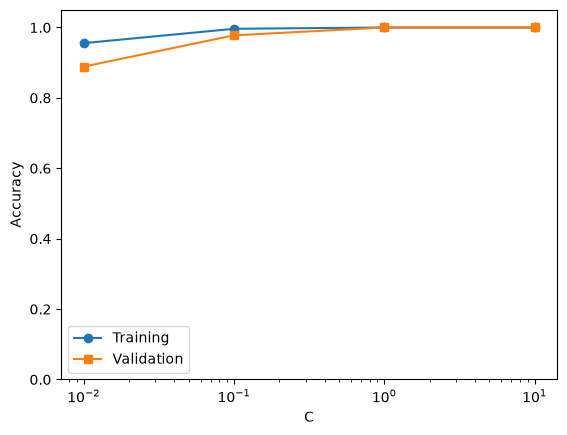

Majority validation baseline: 0.3333333333333333


In [7]:
plt.semilogx(c_values, training_scores, 'o-', label='Training')
plt.semilogx(c_values, validation_scores, 's-', label='Validation')
plt.xlabel('C'); plt.ylabel('Accuracy'); plt.ylim(0, 1.05); plt.legend(); plt.show()
print('Majority validation baseline:', np.bincount(y_val).max()/len(y_val))


## Step 4 — Evaluate the held-out test set
Model selection is complete. Accuracy summarizes overall performance; confusion matrices reveal class-specific failures. Rows below are true classes, columns are predictions. Repeatedly tuning after seeing this result converts the test set into another validation set.


Held-out accuracy: 99.2% (120 samples)


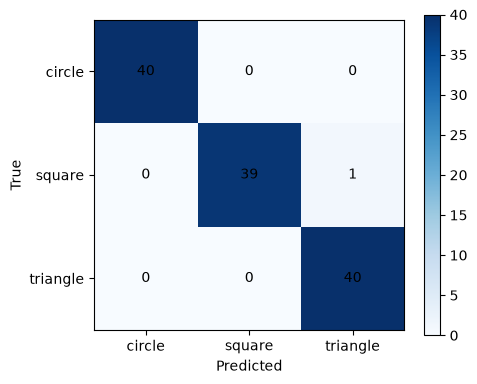

In [8]:
test_predictions = best_model.predict(X_test)[1].ravel().astype(int)
test_accuracy = float(np.mean(test_predictions == y_test))
confusion = np.zeros((3, 3), dtype=int)
np.add.at(confusion, (y_test, test_predictions), 1)
assert confusion.sum() == len(y_test) and test_accuracy > 0.75
print(f'Held-out accuracy: {test_accuracy:.1%} ({len(y_test)} samples)')
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(confusion, cmap='Blues'); fig.colorbar(im, ax=ax)
ax.set(xticks=range(3), yticks=range(3), xticklabels=class_names, yticklabels=class_names,
       xlabel='Predicted', ylabel='True')
for row in range(3):
    for col in range(3): ax.text(col, row, str(confusion[row, col]), ha='center', va='center')
plt.tight_layout(); plt.show()


circle  : precision=1.000, recall=1.000
square  : precision=1.000, recall=0.975
triangle: precision=0.976, recall=1.000


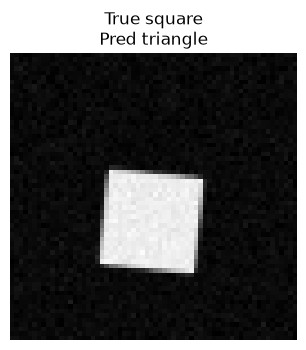

Incorrect held-out examples: 1


In [9]:
tp = np.diag(confusion).astype(float)
precision = np.divide(tp, confusion.sum(axis=0), out=np.zeros(3), where=confusion.sum(axis=0)>0)
recall = np.divide(tp, confusion.sum(axis=1), out=np.zeros(3), where=confusion.sum(axis=1)>0)
for name, p, r in zip(class_names, precision, recall):
    print(f'{name:8s}: precision={p:.3f}, recall={r:.3f}')
wrong = np.flatnonzero(test_predictions != y_test)
examples = wrong[:8] if len(wrong) else np.arange(6)
show_images(list(test_images[examples]),
            [f'True {class_names[y_test[i]]}\nPred {class_names[test_predictions[i]]}' for i in examples], cols=4)
print('Incorrect held-out examples:', len(wrong))


## Step 5 — Test a distribution change
Shift shapes to the right while retaining labels. Some shapes now touch or cross the crop boundary. This robustness set answers a different question from IID test accuracy. Report it separately.


Original test: 99.2%; shifted/cropped diagnostic: 39.2%


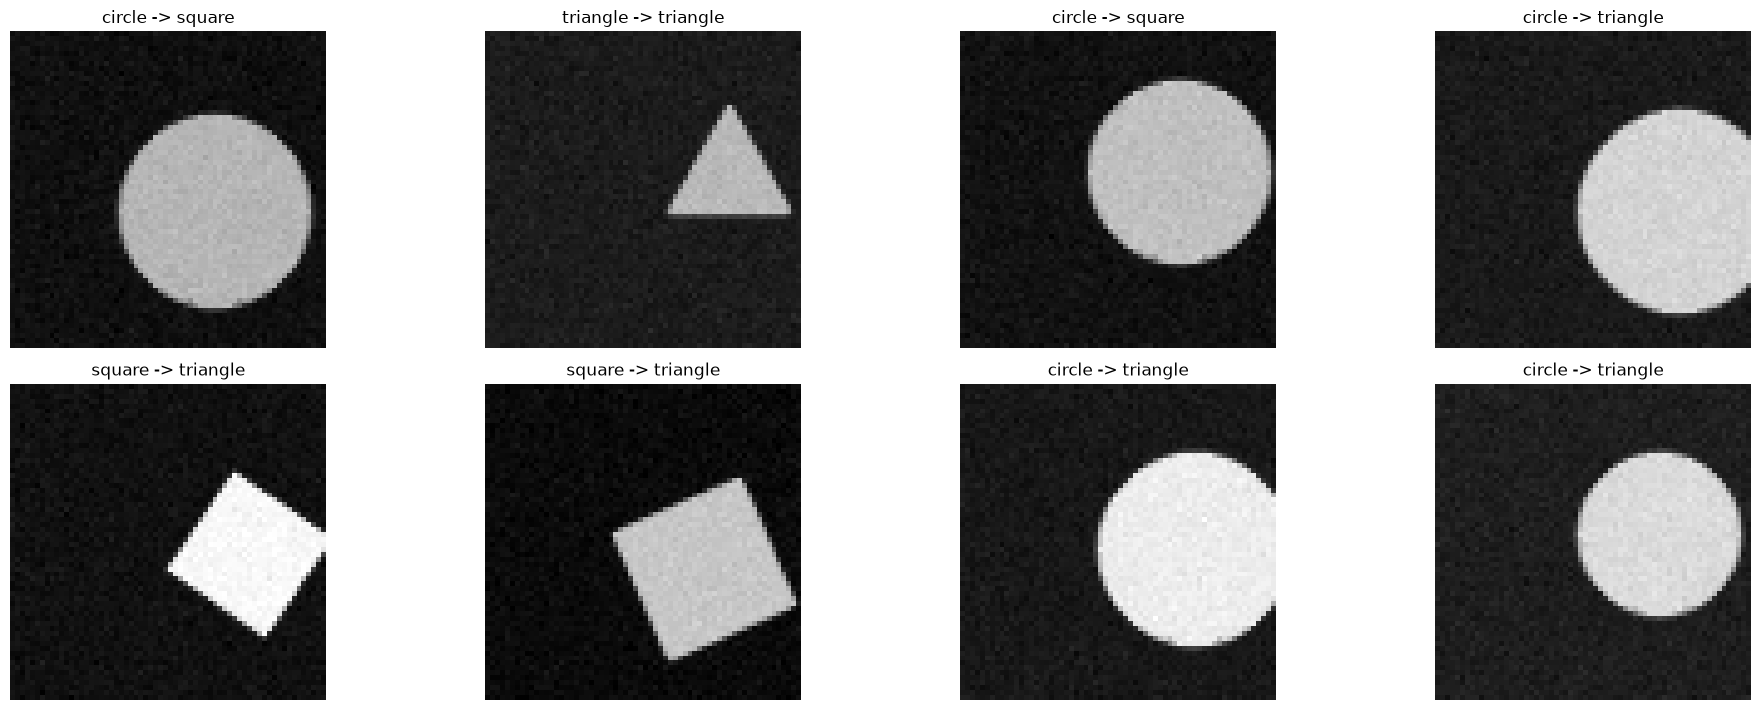

In [10]:
shifted_images, shifted_labels = make_dataset(40, 1604, offset_x=14)
shifted_prediction = best_model.predict(extract_hog(shifted_images))[1].ravel().astype(int)
shifted_accuracy = np.mean(shifted_prediction == shifted_labels)
print(f'Original test: {test_accuracy:.1%}; shifted/cropped diagnostic: {shifted_accuracy:.1%}')
show_images(list(shifted_images[:8]),
            [f'{class_names[t]} -> {class_names[p]}' for t, p in zip(shifted_labels[:8], shifted_prediction[:8])], cols=4)


Possible improvements include detecting and centering the shape or augmenting training positions. Choose changes with a new validation protocol, then evaluate fresh test seeds. Do not improve a reported score by editing its test set.


## Step 6 — Save a reproducible predictor
Record label order, dimensions, grayscale policy, HOG geometry, and split seeds alongside the model. A reloaded predictor should reproduce its predictions.


In [11]:
import json
ml_dir = ROOT / 'outputs' / '16_hog_svm'; ml_dir.mkdir(parents=True, exist_ok=True)
model_path = ml_dir / 'shape_svm.xml'
best_model.save(str(model_path))
metadata = dict(classes=class_names, image_size=[64, 64], input='uint8 grayscale',
                hog=dict(block=[16, 16], stride=[8, 8], cell=[8, 8], bins=9),
                C=c_values[best_index], train_seed=1601, validation_seed=1602, test_seed=1603,
                description='Synthetic shapes; not a general object classifier')
(ml_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
loaded = cv2.ml.SVM_load(str(model_path))
np.testing.assert_array_equal(loaded.predict(X_test)[1].ravel().astype(int), test_predictions)
print('Reloaded predictions match. Saved to:', ml_dir)


Reloaded predictions match. Saved to: C:\Users\Hareram ray\AI\OpencvPractical\outputs\16_hog_svm


### Practice
1. Add a cross as a fourth class, updating generation, label names, and matrix dimensions.
2. Explain how a majority predictor can achieve high accuracy while ignoring minority classes.
3. Fit a nearest-class-centroid baseline using training HOG features and compare validation accuracy.

If adding scaling or PCA, fit it only on training features, then apply the saved transform to other splits.


In [12]:
# Experiment workspace: compute class prototypes from training data only.
centroids = np.stack([X_train[y_train == label].mean(axis=0) for label in range(3)])
print('Centroid matrix:', centroids.shape)


Centroid matrix: (3, 1764)


### Worked solutions
Nearest-centroid classification chooses the closest class mean. It learns three prototypes and has a different bias from the SVM. The comparison below remains on validation data.


In [13]:
distances = ((X_val[:, None, :] - centroids[None, :, :])**2).sum(axis=2)
centroid_predictions = distances.argmin(axis=1)
print('Nearest-centroid validation accuracy:', np.mean(centroid_predictions == y_val))
imbalanced = np.array([0]*90 + [1]*5 + [2]*5)
print('Imbalanced majority accuracy:', np.mean(np.zeros_like(imbalanced) == imbalanced))
print('Minority recall is zero; balanced accuracy is (1+0+0)/3 =', 1/3)


Nearest-centroid validation accuracy: 0.8444444444444444
Imbalanced majority accuracy: 0.9
Minority recall is zero; balanced accuracy is (1+0+0)/3 = 0.3333333333333333


### References
- [OpenCV HOGDescriptor](https://docs.opencv.org/4.x/d5/d33/structcv_1_1HOGDescriptor.html)
- [OpenCV SVM introduction](https://docs.opencv.org/4.x/d1/d73/tutorial_introduction_to_svm.html)
- [OpenCV SVM API](https://docs.opencv.org/4.x/d1/d2d/classcv_1_1ml_1_1SVM.html)

Next: distinguish training a classical model from running a neural network with OpenCV DNN.
